# Import Modules

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Parameters

In [2]:
start_date="01-10-2026"
end_date="10-11-2026"

days_segment = 12

api = "http://10.7.32.34/cdm/Quotations/GetRData/91535c0a-31eb-4906-b895-2cd0fdcf36eb?startDate="+start_date+"&endDate="+end_date+"&dates=true&simulation=0"

# Import Data

In [3]:
df=pd.read_csv(api)

In [4]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df.index.name=None

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 985 entries, 2026-10-01 00:00:00 to 2026-11-10 23:00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   985 non-null    float64
dtypes: float64(1)
memory usage: 15.4 KB


In [6]:
df.tail(24).mean()

value    337.907812
dtype: float64

<Axes: >

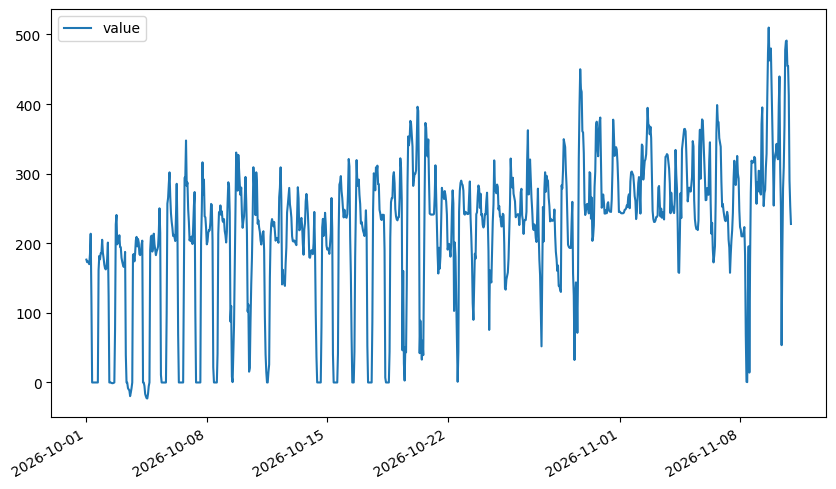

In [7]:
df.plot(figsize=(10,6))

In [8]:
#df.to_excel("FW_Curve_hourly.xlsx")

# Simplistic Calculations (hour average)

In [9]:
monthly_average_series = df.groupby(df.index.month)["value"].mean()

In [10]:
monthly_average_series

10    197.065919
11    284.458521
Name: value, dtype: float64

## 1. Calculate average per hour across days

In [11]:
hourly_average_series = df.groupby(df.index.hour)["value"].mean()

## 2. Sort based on values (ascending)

In [12]:
hourly_average_sorted_series = hourly_average_series.sort_values()

In [13]:
hourly_average_sorted_series

11    106.949573
10    113.319695
12    114.197622
13    118.871280
9     123.880244
14    136.350549
8     183.544146
15    191.393659
4     225.238537
3     227.139329
1     229.214634
2     229.252738
0     232.873354
23    237.400915
5     240.509207
7     249.962012
16    257.689085
22    266.899329
6     271.996890
21    284.952073
20    297.067622
17    297.656646
18    301.376829
19    302.627500
Name: value, dtype: float64

### 2.1. Keep n cheapest hours

In [14]:
lowest_prices_series = hourly_average_series.nsmallest(days_segment).sort_values()

In [15]:
lowest_prices_series

11    106.949573
10    113.319695
12    114.197622
13    118.871280
9     123.880244
14    136.350549
8     183.544146
15    191.393659
4     225.238537
3     227.139329
1     229.214634
2     229.252738
Name: value, dtype: float64

In [16]:
print("Average of cheaper hours: {}".format(lowest_prices_series.mean()))

Average of cheaper hours: 166.61266719899342


### 2.2. Keep n most expensive hours

In [17]:
higher_prices_series = hourly_average_series.nlargest(days_segment).sort_values()

In [18]:
higher_prices_series

0     232.873354
23    237.400915
5     240.509207
7     249.962012
16    257.689085
22    266.899329
6     271.996890
21    284.952073
20    297.067622
17    297.656646
18    301.376829
19    302.627500
Name: value, dtype: float64

In [19]:
print("Average of expensive hours: {}".format(higher_prices_series.mean()))

Average of expensive hours: 270.08428861788616


# Realistic Calculation (n smallest / n largest per day)

In [20]:
lowest_n_series = (
    df.groupby(df.index.normalize(), group_keys=False)
      .apply(lambda day: day.nsmallest(12, "value"))
      .sort_index())
highest_n_series = (
    df.groupby(df.index.normalize(), group_keys=False)
      .apply(lambda day: day.nlargest(12, "value"))
      .sort_index())

In [21]:
#lowest_n_series.head(12).sort_values(by="value")

In [22]:
#highest_n_series.head(24)

In [23]:
avg_lowest_n_series = lowest_n_series.resample('D').mean()
avg_highest_n_series = highest_n_series.resample('D').mean()

In [24]:
min_of_means=avg_lowest_n_series.mean()
max_of_means=avg_highest_n_series.mean()

print("Mean of Min: {} \nMean of Max: {}".format(min_of_means.values[0], max_of_means.values[0]))
print("Std of Min: {} \nStd of Max: {}".format(avg_lowest_n_series.std().values[0], avg_highest_n_series.std().values[0]))

Mean of Min: 156.49900406504065 
Mean of Max: 280.1796951219512
Std of Min: 75.93092015794308 
Std of Max: 52.814627049130564


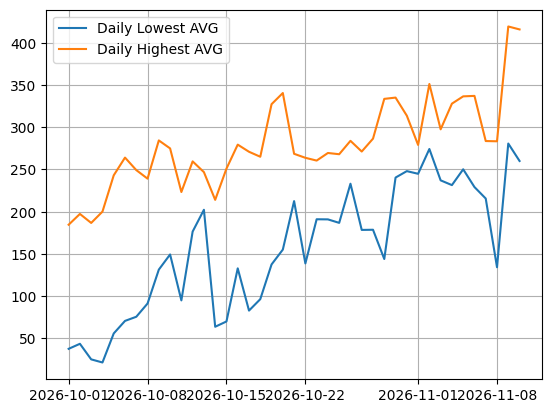

In [25]:
plt.figure()

plt.plot(avg_lowest_n_series.index, avg_lowest_n_series.value, label="Daily Lowest AVG")
plt.plot(avg_highest_n_series.index, avg_highest_n_series.value, label="Daily Highest AVG")

plt.legend()
plt.grid()

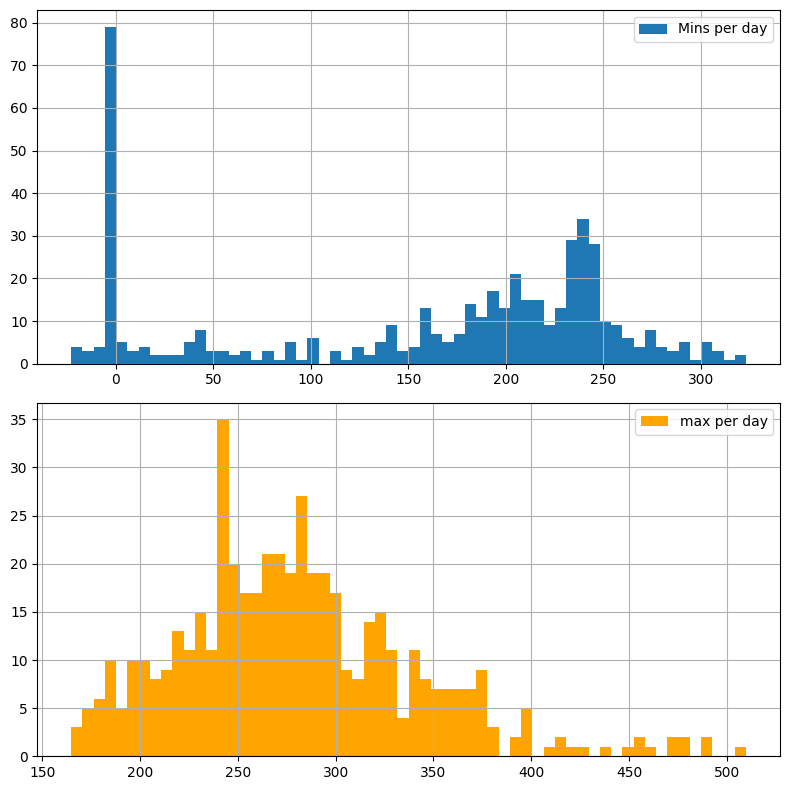

In [26]:
plt.figure(figsize=(8,8))
plt.subplot(2,1,1)
plt.hist(lowest_n_series, bins=60, label="Mins per day");
plt.grid()
plt.legend()

plt.subplot(2,1,2)
plt.hist(highest_n_series, bins=60, label="max per day", color="orange");
plt.tight_layout()
plt.grid()
plt.legend()

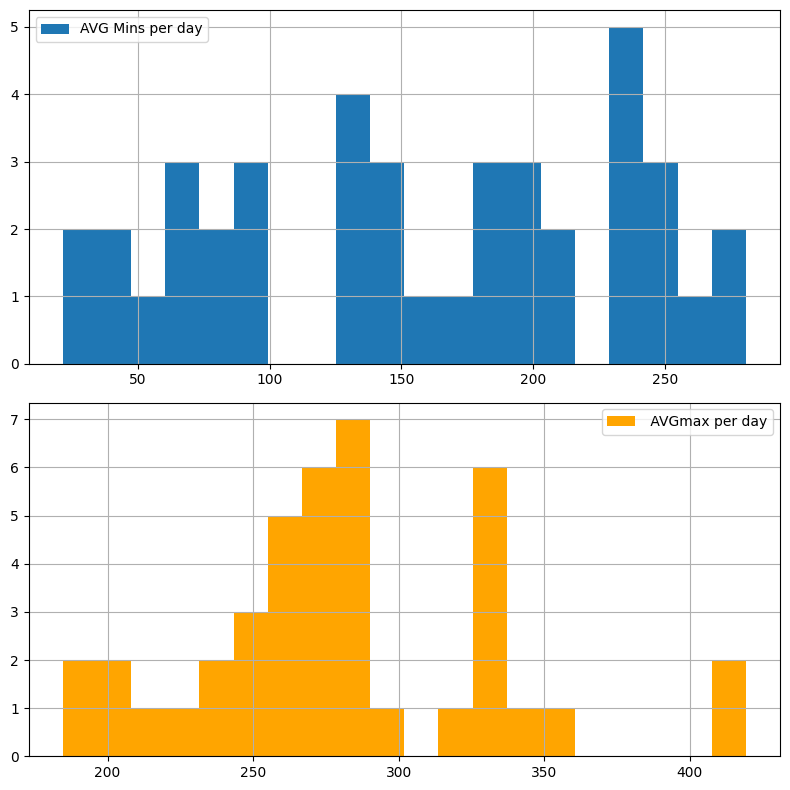

In [27]:
plt.figure(figsize=(8,8))
plt.subplot(2,1,1)
plt.hist(avg_lowest_n_series, bins=20, label="AVG Mins per day");
plt.grid()
plt.legend()

plt.subplot(2,1,2)
plt.hist(avg_highest_n_series, bins=20, label=" AVGmax per day", color="orange");
plt.tight_layout()
plt.grid()
plt.legend()